# Week 3 — Model development (step 1: single models, no tuning)
**Project:** RUL prediction of turbofan engines — NASA C-MAPSS FD002
**Team:** Thiya Papuge, Mathis Le Texier, Hugo De Benetti

This notebook is **step 1** of Week 3. Its goal is to measure what we gain over the Week-2 baseline (Ridge, current cycle, RMSE ≈ 23 in CV) with:
1. **history features** (rolling window over the last 30 cycles), and
2. **non-linear models** (decision tree, random forest, gradient boosting, SVR),

using **fixed, a-priori hyperparameters** (no GridSearchCV, no Bagging, no Voting yet).

**Step 2** (Lab 6) will add, on top of the same functions: `GridSearchCV` with `GroupKFold`, `BaggingRegressor` (tree and SVR) and `VotingRegressor`.
The placeholders are in Section 8. Doing step 1 first gives an honest reference: we will know exactly how much tuning and ensembling add.

In [1]:
import sys, warnings
from pathlib import Path
# Find the project root (folder that contains src/cmapss.py) whatever the working directory is
_here = Path.cwd().resolve()
_cands = [p for p in [_here, *_here.parents] if (p / 'src' / 'cmapss.py').exists()]
_cands += [f.parent.parent for pat in ('*/src/cmapss.py', '*/*/src/cmapss.py', '*/*/*/src/cmapss.py') for f in _here.glob(pat)]
assert _cands, f'src/cmapss.py not found from {_here}: open the notebook from the project folder'
ROOT = _cands[0]
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

from src.cmapss import (SENSORS, CONSTANT_SENSORS, QUANTISED_SENSORS, RUL_CAP, RANDOM_STATE,
                        ConditionNormalizer, WindowFeatures, SubsampledRegressor,
                        cross_validate_model, regression_report, last_cycle)

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 160, 'display.max_columns', 40)
print('Project root:', ROOT)

Project root: /mnt/attach/project-files/week2/Group_XX_DS_Project


## 1. Data and evaluation protocol (unchanged from Week 2)
* Input: the clean files produced by notebook 02 (`data/processed/`), raw sensor values, 14 continuous sensors kept.
* Target: `RUL_capped = min(RUL, 125)`.
* Validation: **the same 5-fold GroupKFold by engine** as Week 2 (GroupKFold is deterministic, so the folds are identical and the scores are directly comparable).
* Scores: RMSE / MAE on all validation rows, and on **one random cut per engine** (mimics the test set, used for model selection); NASA score per engine.
* Test: 259 NASA engines, last observed cycle, **used once at the end**.

In [2]:
DATA = ROOT / 'data' / 'processed'
train = pd.read_csv(DATA / 'train_clean.csv')
test = pd.read_csv(DATA / 'test_clean.csv')
KEEP_14 = [s for s in SENSORS if s not in CONSTANT_SENSORS + QUANTISED_SENSORS]

X, y, groups = train, train['RUL_capped'], train['engine_uid']
folds = list(GroupKFold(n_splits=5).split(X, y, groups))
for tr_idx, va_idx in folds:
    assert not set(groups.iloc[tr_idx]) & set(groups.iloc[va_idx])
print(train.shape, test.shape, '| 14 sensors:', KEEP_14)

(53759, 26) (33991, 26) | 14 sensors: ['T24', 'T30', 'T50', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'NRc', 'BPR', 'htBleed', 'W31', 'W32']


## 2. Feature engineering: history window
A single cycle is noisy (Week 2: the normalised sensors have a noise of ~1 std per cycle, while degradation moves them by ~2 std over the whole life).
Averaging the recent past reduces the noise, and the **slope** tells whether the sensor is currently drifting.

For each of the 14 condition-normalised sensors, `WindowFeatures` (in `src/cmapss.py`) builds:

| Feature | Definition | Why |
|---|---|---|
| `s` | z-score of the current cycle (as in Week 2) | latest information |
| `s_mean30` | mean of the last 30 cycles (fewer at the start of life) | de-noised level of degradation |
| `s_slope30` | least-squares slope vs cycle over the last 30 cycles | speed of degradation |

plus `cycle` (age of the engine, known at prediction time). Total: 14 × 3 + 1 = **43 features**.

**Leakage control.**
* The only learned part is the `ConditionNormalizer` (KMeans + per-condition mean/std). It is inside the pipeline → re-fitted on each training fold.
* Rolling features use **only past cycles of the same engine**: they are *causal*. A test engine cut at cycle 80 gets exactly the same features as if we
  had its full trajectory. The next cell checks this property explicitly.
* Why 30 cycles: it is the window announced in the Week-1 specification; it is shorter than the shortest test engine (21 cycles is the only exception,
  handled by `min_periods=1`). The window size is a hyperparameter to tune in step 2.

In [3]:
wf = WindowFeatures(sensors=KEEP_14, window=30).fit(train)
F = wf.transform(train)
print('feature matrix:', F.shape)

# Causality check: features at cycle c computed from the truncated trajectory == from the full trajectory
rng = np.random.default_rng(RANDOM_STATE)
for uid in rng.choice(train['engine_uid'].unique(), 10, replace=False):
    eng = train[train['engine_uid'] == uid]
    c = int(rng.integers(5, eng['cycle'].max()))
    truncated = eng[eng['cycle'] <= c]
    assert np.allclose(wf.transform(truncated).iloc[-1].to_numpy(), F.loc[truncated.index[-1]].to_numpy())
print('Causality check passed on 10 random engines / cut points: features never use future cycles.')

feature matrix: (53759, 43)


Causality check passed on 10 random engines / cut points: features never use future cycles.


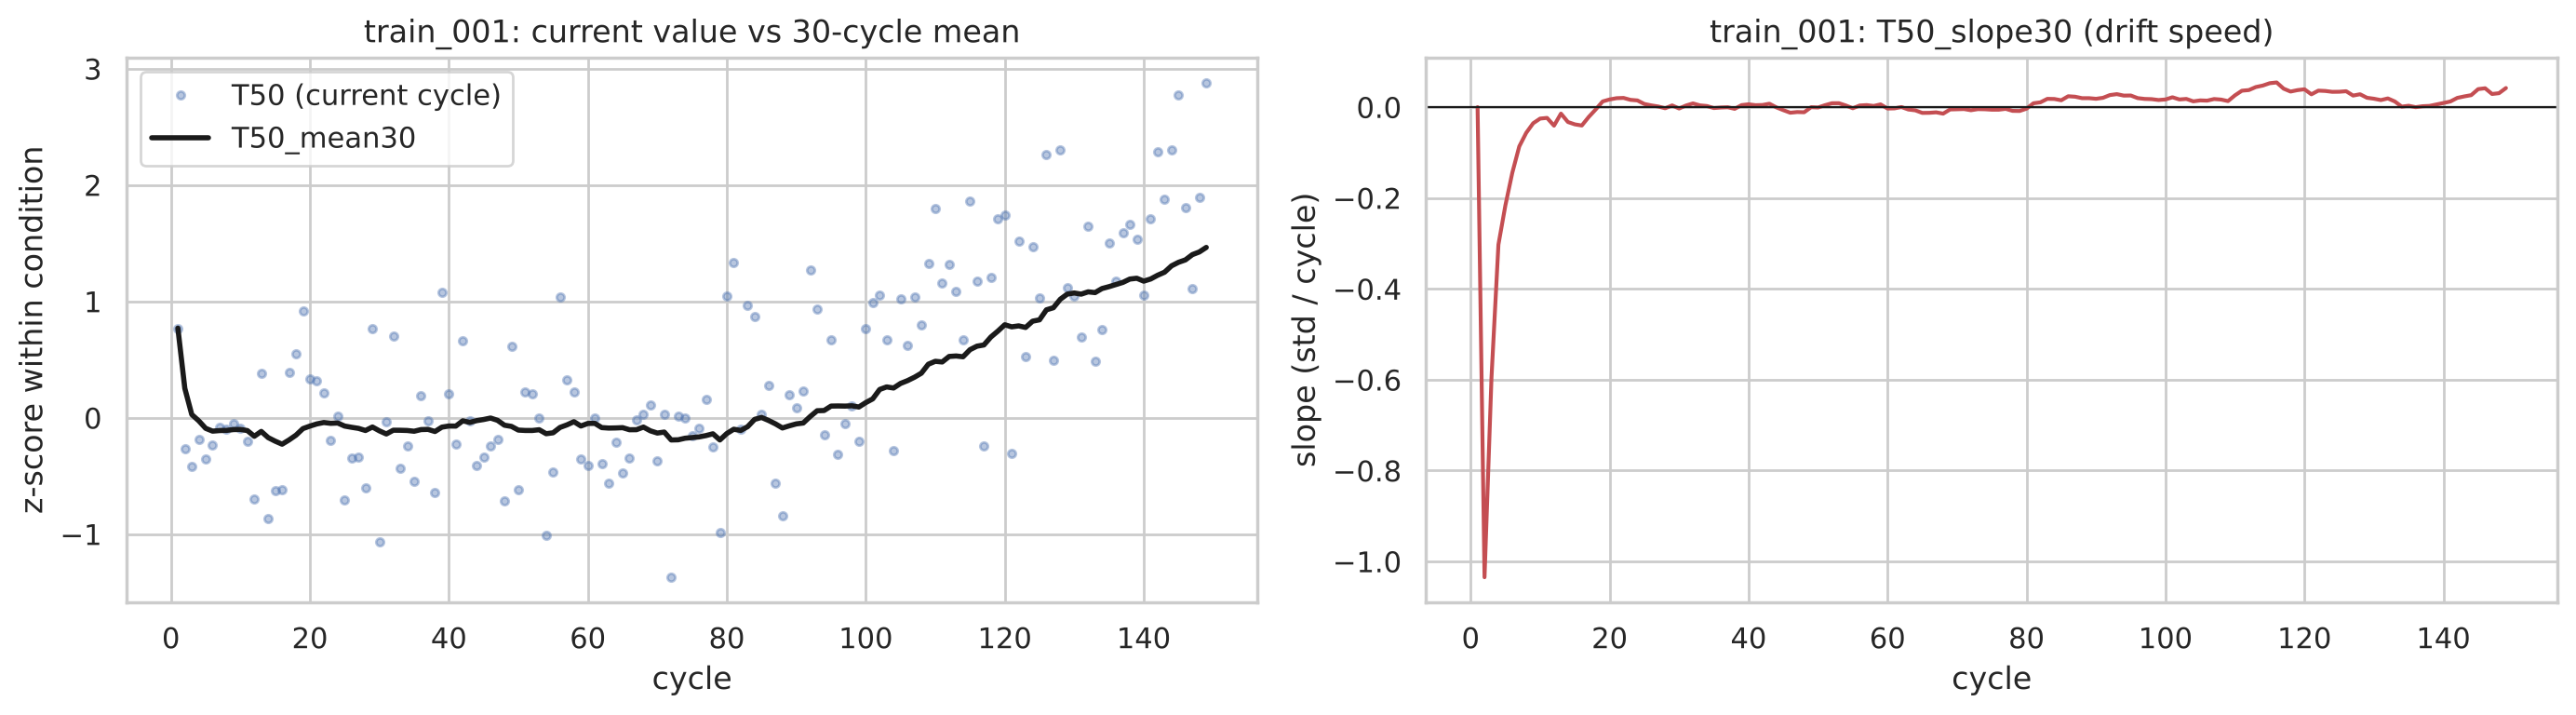

Top 10 |correlation| with capped RUL:
htBleed_mean30    0.799
T24_mean30        0.792
T30_mean30        0.791
T50_mean30        0.791
Ps30_mean30       0.782
BPR_mean30        0.781
Ps30              0.771
cycle             0.744
W31_mean30        0.741
T50               0.738


In [4]:
eng = train[train['engine_uid'] == 'train_001']
Fe = F.loc[eng.index]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(eng['cycle'], Fe['T50'], '.', alpha=.4, label='T50 (current cycle)')
ax[0].plot(eng['cycle'], Fe['T50_mean30'], 'k', lw=2, label='T50_mean30')
ax[0].set(xlabel='cycle', ylabel='z-score within condition', title='train_001: current value vs 30-cycle mean'); ax[0].legend()
ax[1].plot(eng['cycle'], Fe['T50_slope30'], 'C3')
ax[1].axhline(0, color='k', lw=.8)
ax[1].set(xlabel='cycle', ylabel='slope (std / cycle)', title='train_001: T50_slope30 (drift speed)')
plt.tight_layout(); plt.show()

corr = F.corrwith(train['RUL_capped']).abs().sort_values(ascending=False)
print('Top 10 |correlation| with capped RUL:'); print(corr.head(10).round(3).to_string())

## 3. Models (step 1: fixed hyperparameters)
All models share the same pipeline: `WindowFeatures → StandardScaler → model`. The scaler is required for Ridge and SVR (distance/penalty
based) and harmless for trees. Hyperparameters are **chosen a priori** from usual defaults, not tuned, so the CV score is an unbiased estimate.

| Model | Hyperparameters (fixed) | Reason |
|---|---|---|
| Mean | — | floor |
| Ridge, current cycle | alpha = 1 | **Week-2 baseline**, reproduced |
| Ridge, window | alpha = 1 | effect of the features alone, model unchanged |
| HistGradientBoosting, current cycle | sklearn defaults | effect of the model alone, features unchanged |
| Decision tree | max_depth = 10, min_samples_leaf = 20 | interpretable non-linear model; the limits avoid a fully grown (over-fitted) tree |
| Random forest | 200 trees, min_samples_leaf = 5, max_features = 0.33 | averages many decorrelated trees → lower variance than one tree |
| HistGradientBoosting, window | sklearn defaults (100 iterations, lr 0.1, early stopping off at this size) | strong default for tabular data, fast |
| SVR (RBF kernel) | C = 10, epsilon = 1, gamma = 'scale', trained on 1 cycle in 5 | non-linear kernel model, base learner of Lab 6; its cost grows ~n², so it is trained on 1/5 of the rows (~8 600) |

The two "ablation" rows (Ridge window, HGB current cycle) separate the gain due to **features** from the gain due to the **model**.

In [5]:
def pipe(model, features='window'):
    feat = (WindowFeatures(sensors=KEEP_14, window=30) if features == 'window'
            else ConditionNormalizer(sensors=KEEP_14))
    return Pipeline([('features', feat), ('scale', StandardScaler()), ('model', model)])

def make_models():
    # Step 2 will add GridSearchCV / Bagging / Voting entries to this same dictionary.
    return {
        'Mean':                    DummyRegressor(strategy='mean'),
        'Ridge (current cycle)':   pipe(Ridge(alpha=1.0), features='current'),
        'Ridge (window)':          pipe(Ridge(alpha=1.0)),
        'HGB (current cycle)':     pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE), features='current'),
        'Decision tree':           pipe(DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=RANDOM_STATE)),
        'Random forest':           pipe(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.33,
                                                              n_jobs=-1, random_state=RANDOM_STATE)),
        'HGB (window)':            pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
        'SVR (window)':            pipe(SubsampledRegressor(SVR(kernel='rbf', C=10, epsilon=1.0, gamma='scale'), step=5)),
    }

## 4. Cross-validation results

In [6]:
cv = {}
for name, model in make_models().items():
    cv[name] = cross_validate_model(model, X, y, folds)
    print(f"{name:24s} RMSE random cut = {cv[name]['RMSE random cut'].mean():6.2f}  "
          f"(fit {cv[name]['fit time (s)'].mean():5.1f} s / fold)")

Mean                     RMSE random cut =  43.03  (fit   0.0 s / fold)


Ridge (current cycle)    RMSE random cut =  23.05  (fit   0.7 s / fold)


Ridge (window)           RMSE random cut =  21.79  (fit   2.0 s / fold)


HGB (current cycle)      RMSE random cut =  20.94  (fit   1.0 s / fold)


Decision tree            RMSE random cut =  17.75  (fit   3.4 s / fold)


Random forest            RMSE random cut =  14.68  (fit  22.5 s / fold)


HGB (window)             RMSE random cut =  14.40  (fit   2.7 s / fold)


SVR (window)             RMSE random cut =  16.63  (fit   5.9 s / fold)


In [7]:
cv_mean = pd.DataFrame({n: r.drop(columns='fold').mean() for n, r in cv.items()}).T
cv_std = pd.DataFrame({n: r.drop(columns='fold').std() for n, r in cv.items()}).T
table = cv_mean.round(2).astype(str) + ' ± ' + cv_std.round(2).astype(str)
table['fit time (s)'] = cv_mean['fit time (s)'].round(1)
table.loc[cv_mean['RMSE random cut'].sort_values().index]

,RMSE all rows,MAE all rows,RMSE random cut,MAE random cut,NASA score / engine (random cut),fit time (s)
HGB (window),13.57 ± 0.55,9.18 ± 0.34,14.4 ± 3.21,10.27 ± 2.02,4.56 ± 2.65,2.7
Random forest,13.91 ± 0.63,9.56 ± 0.42,14.68 ± 2.64,10.86 ± 1.97,4.33 ± 2.4,22.5
SVR (window),15.4 ± 0.59,10.71 ± 0.48,16.63 ± 1.96,12.29 ± 1.55,7.22 ± 3.78,5.9
Decision tree,16.76 ± 0.53,11.03 ± 0.38,17.75 ± 3.39,12.53 ± 2.17,11.87 ± 10.39,3.4
HGB (current cycle),19.75 ± 0.77,14.52 ± 0.67,20.94 ± 2.53,15.38 ± 1.9,24.02 ± 14.72,1.0
Ridge (window),20.37 ± 0.49,16.3 ± 0.42,21.79 ± 1.74,17.96 ± 2.13,11.56 ± 3.15,2.0
Ridge (current cycle),21.65 ± 0.59,17.37 ± 0.53,23.05 ± 2.29,18.77 ± 2.48,16.39 ± 7.04,0.7
Mean,41.67 ± 0.0,36.95 ± 0.0,43.03 ± 3.2,37.51 ± 2.88,378.53 ± 203.35,0.0


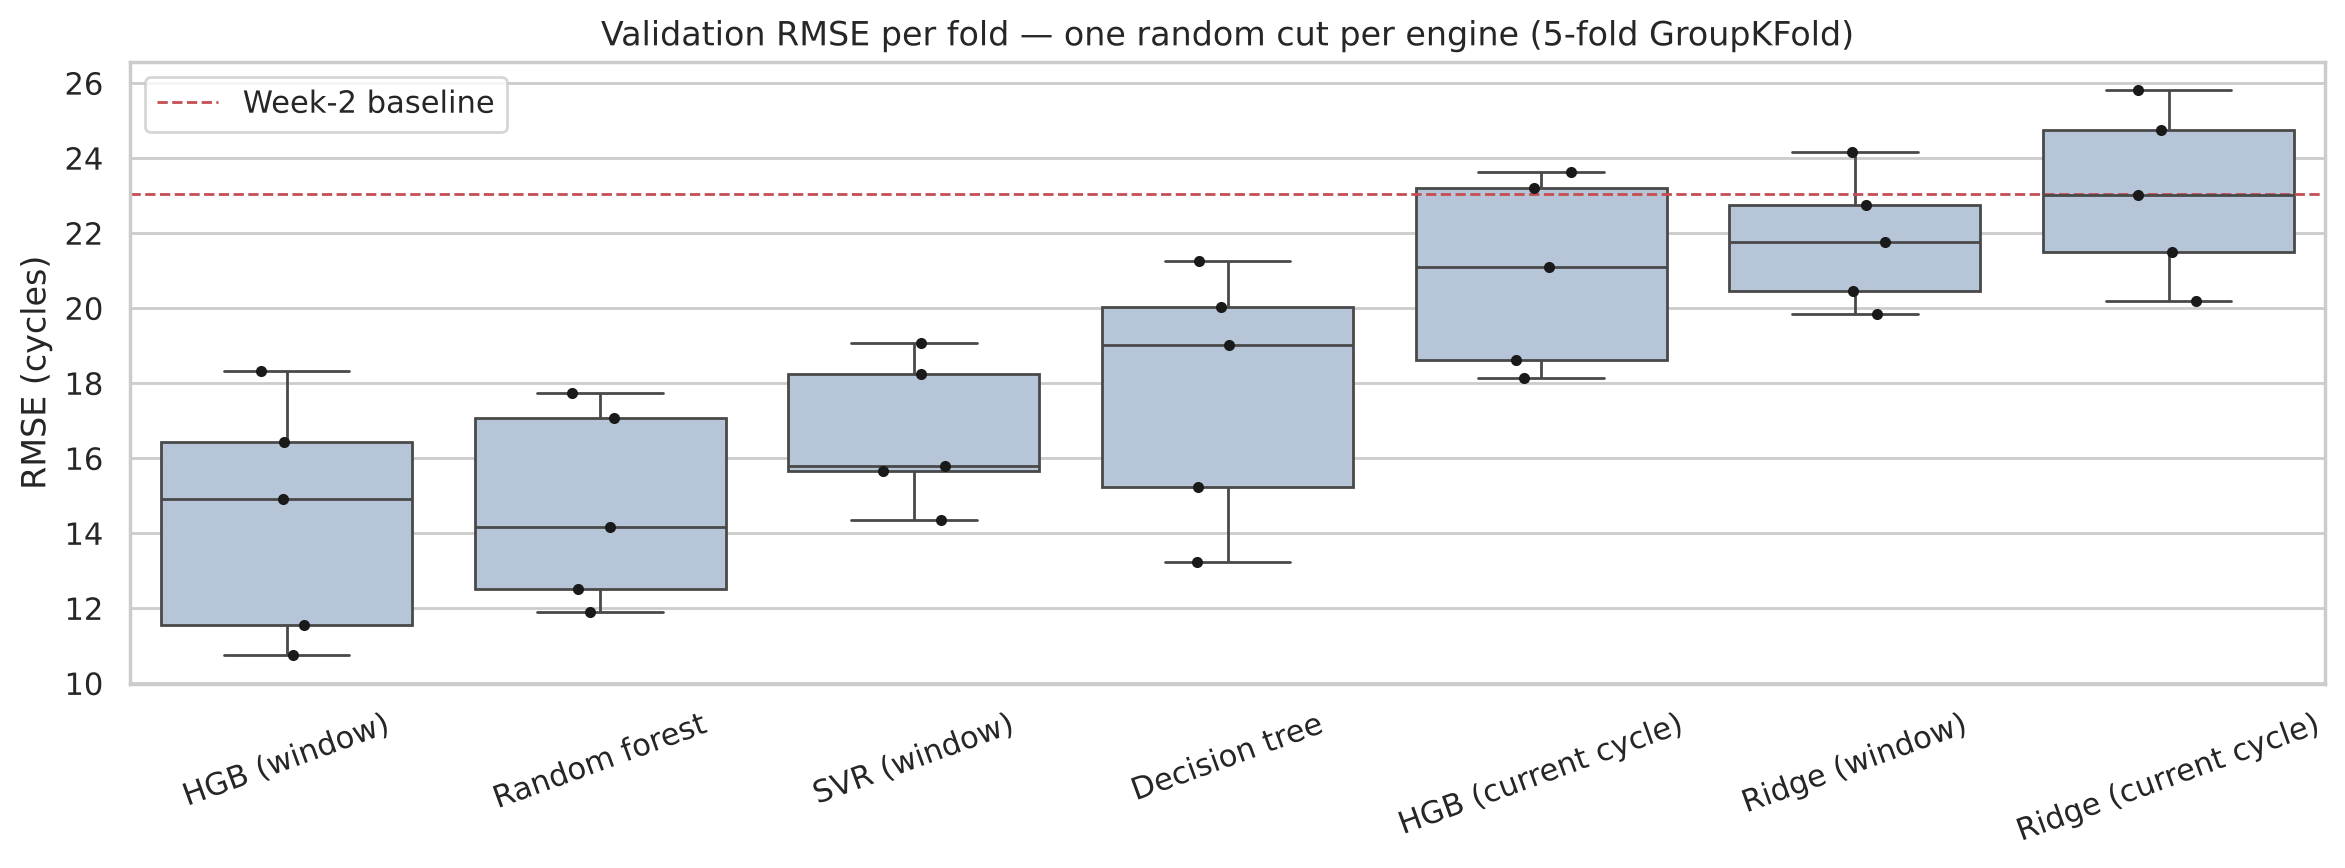

In [8]:
order = cv_mean['RMSE random cut'].sort_values().index.drop('Mean')
plot_df = pd.concat({n: cv[n]['RMSE random cut'] for n in order}, axis=1)
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=plot_df, ax=ax, color='lightsteelblue'); sns.stripplot(data=plot_df, ax=ax, color='k', size=4)
ax.axhline(cv_mean.loc['Ridge (current cycle)', 'RMSE random cut'], color='r', ls='--', lw=1, label='Week-2 baseline')
ax.set(ylabel='RMSE (cycles)', title='Validation RMSE per fold — one random cut per engine (5-fold GroupKFold)')
ax.tick_params(axis='x', rotation=20); ax.legend(); plt.tight_layout(); plt.show()

## 5. Where does the gain come from? (features vs model)

In [9]:
r = cv_mean['RMSE random cut']
ablation = pd.DataFrame({'current cycle': [r['Ridge (current cycle)'], r['HGB (current cycle)']],
                         'window (30 cycles)': [r['Ridge (window)'], r['HGB (window)']]},
                        index=['Ridge (linear)', 'HGB (non-linear)']).round(2)
ablation

,current cycle,window (30 cycles)
Ridge (linear),23.05,21.79
HGB (non-linear),20.94,14.40


In [10]:
# Extra ablation: how much does the model rely on the engine age (`cycle`)?
no_cycle = Pipeline([('features', WindowFeatures(sensors=KEEP_14, window=30, include_cycle=False)),
                     ('scale', StandardScaler()), ('model', HistGradientBoostingRegressor(random_state=RANDOM_STATE))])
cv_nc = cross_validate_model(no_cycle, X, y, folds)
print(f"HGB (window) with cycle    : RMSE random cut = {cv_mean.loc['HGB (window)', 'RMSE random cut']:.2f}")
print(f"HGB (window) without cycle : RMSE random cut = {cv_nc['RMSE random cut'].mean():.2f} ± {cv_nc['RMSE random cut'].std():.2f}")

HGB (window) with cycle    : RMSE random cut = 14.40
HGB (window) without cycle : RMSE random cut = 14.98 ± 3.38


Read the 2×2 table row by row (effect of the features at fixed model) and column by column (effect of the model at fixed features).
The interpretation is written in the conclusion (Section 9) after looking at the numbers.

## 6. Final evaluation on the NASA test set (run once)
Model selection is done **on the CV table above** (lowest RMSE on random cuts). All models are then re-fitted on the 260 training engines and
evaluated on the test set; we show all of them for transparency, but the choice was made before looking at the test.
Features are computed on the **full observed test trajectories** (they are causal), then only the last cycle of each engine is scored.

In [11]:
best_name = cv_mean['RMSE random cut'].idxmin()
print('Selected on CV:', best_name)

test_last_idx = last_cycle(test).index
rows, fitted = {}, {}
for name, model in make_models().items():
    m = clone(model).fit(X, y)
    fitted[name] = m
    pred = pd.Series(np.clip(m.predict(test), 0, None), index=test.index).loc[test_last_idx]
    capped = regression_report(test.loc[test_last_idx, 'RUL_capped'], pred)
    true = regression_report(test.loc[test_last_idx, 'RUL'], pred)
    rows[name] = {'CV RMSE (random cut)': cv_mean.loc[name, 'RMSE random cut'],
                  'test RMSE (capped)': capped['RMSE'], 'test MAE (capped)': capped['MAE'],
                  'test NASA (capped)': capped['NASA score'], 'test RMSE (true RUL)': true['RMSE']}
test_table = pd.DataFrame(rows).T.sort_values('CV RMSE (random cut)')
test_table.round(2)

Selected on CV: HGB (window)


,CV RMSE (random cut),test RMSE (capped),test MAE (capped),test NASA (capped),test RMSE (true RUL)
HGB (window),14.40,13.14,9.48,788.06,25.52
Random forest,14.68,13.02,9.41,810.22,25.75
SVR (window),16.63,13.97,10.33,963.06,25.68
Decision tree,17.75,15.11,10.69,1357.44,26.46
HGB (current cycle),20.94,17.82,13.04,4453.91,29.75
Ridge (window),21.79,19.98,16.79,1980.95,31.50
Ridge (current cycle),23.05,20.91,16.96,2873.45,32.35
Mean,43.03,44.93,38.14,115589.85,54.08


## 7. Error analysis of the selected model

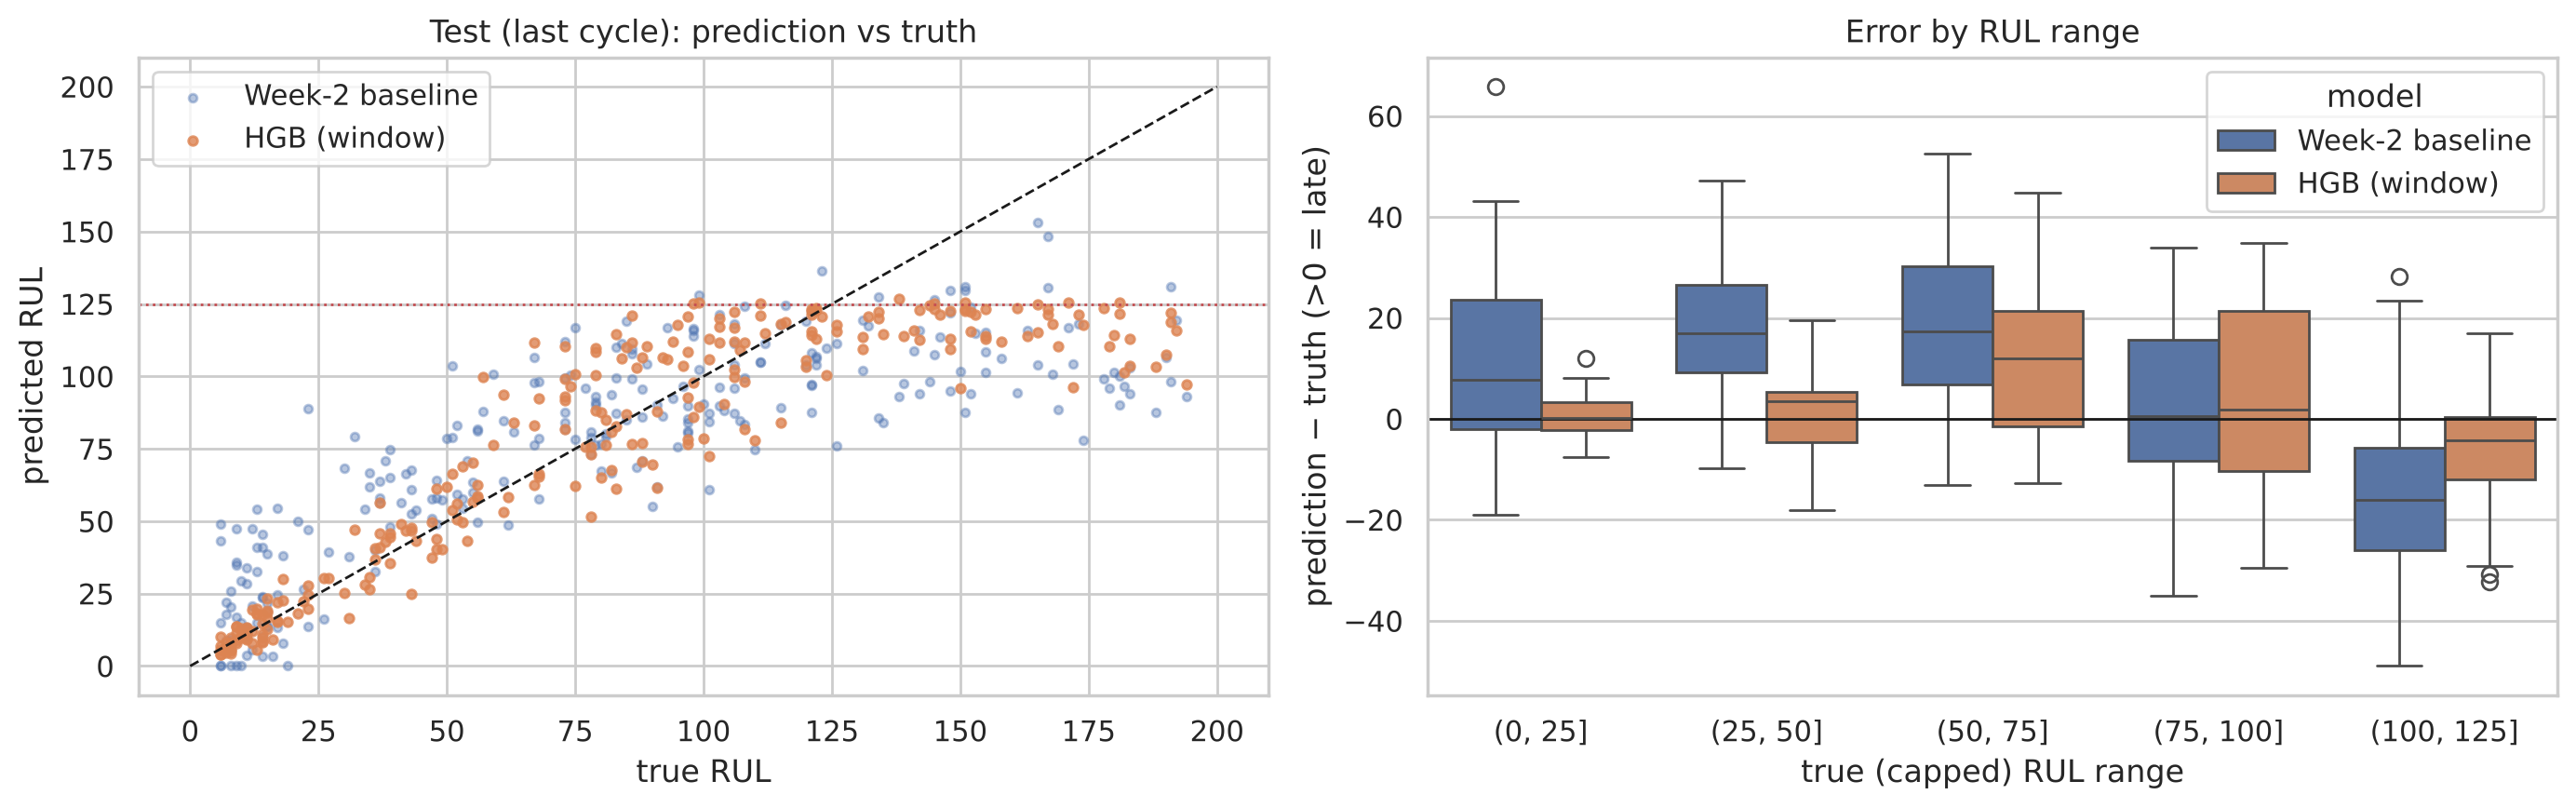

Late predictions (> +10 cycles) on engines with RUL <= 50: 6% (baseline: 50%)


In [12]:
best = fitted[best_name]
tl = test.loc[test_last_idx]
pred = np.clip(best.predict(test), 0, None)
pred = pd.Series(pred, index=test.index).loc[test_last_idx].to_numpy()
base = pd.Series(np.clip(fitted['Ridge (current cycle)'].predict(test), 0, None), index=test.index).loc[test_last_idx].to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(tl['RUL'], base, s=10, alpha=.4, label='Week-2 baseline')
ax[0].scatter(tl['RUL'], pred, s=12, alpha=.8, label=best_name)
ax[0].plot([0, 200], [0, 200], 'k--', lw=1); ax[0].axhline(RUL_CAP, color='r', ls=':', lw=1)
ax[0].set(xlabel='true RUL', ylabel='predicted RUL', title='Test (last cycle): prediction vs truth'); ax[0].legend()

bins = pd.cut(tl['RUL_capped'], [0, 25, 50, 75, 100, 125])
err = pd.DataFrame({'Week-2 baseline': base - tl['RUL_capped'].to_numpy(), best_name: pred - tl['RUL_capped'].to_numpy(),
                    'bin': bins.astype(str).to_numpy()}).melt(id_vars='bin', var_name='model', value_name='error')
sns.boxplot(data=err, x='bin', y='error', hue='model', ax=ax[1], order=[str(b) for b in bins.cat.categories])
ax[1].axhline(0, color='k', lw=1)
ax[1].set(xlabel='true (capped) RUL range', ylabel='prediction − truth (>0 = late)', title='Error by RUL range')
plt.tight_layout(); plt.show()

late = pd.Series(pred - tl['RUL_capped'].to_numpy())
print(f'Late predictions (> +10 cycles) on engines with RUL <= 50: '
      f'{(late[(tl["RUL_capped"] <= 50).to_numpy()] > 10).mean():.0%} (baseline: '
      f'{((base - tl["RUL_capped"].to_numpy())[(tl["RUL_capped"] <= 50).to_numpy()] > 10).mean():.0%})')

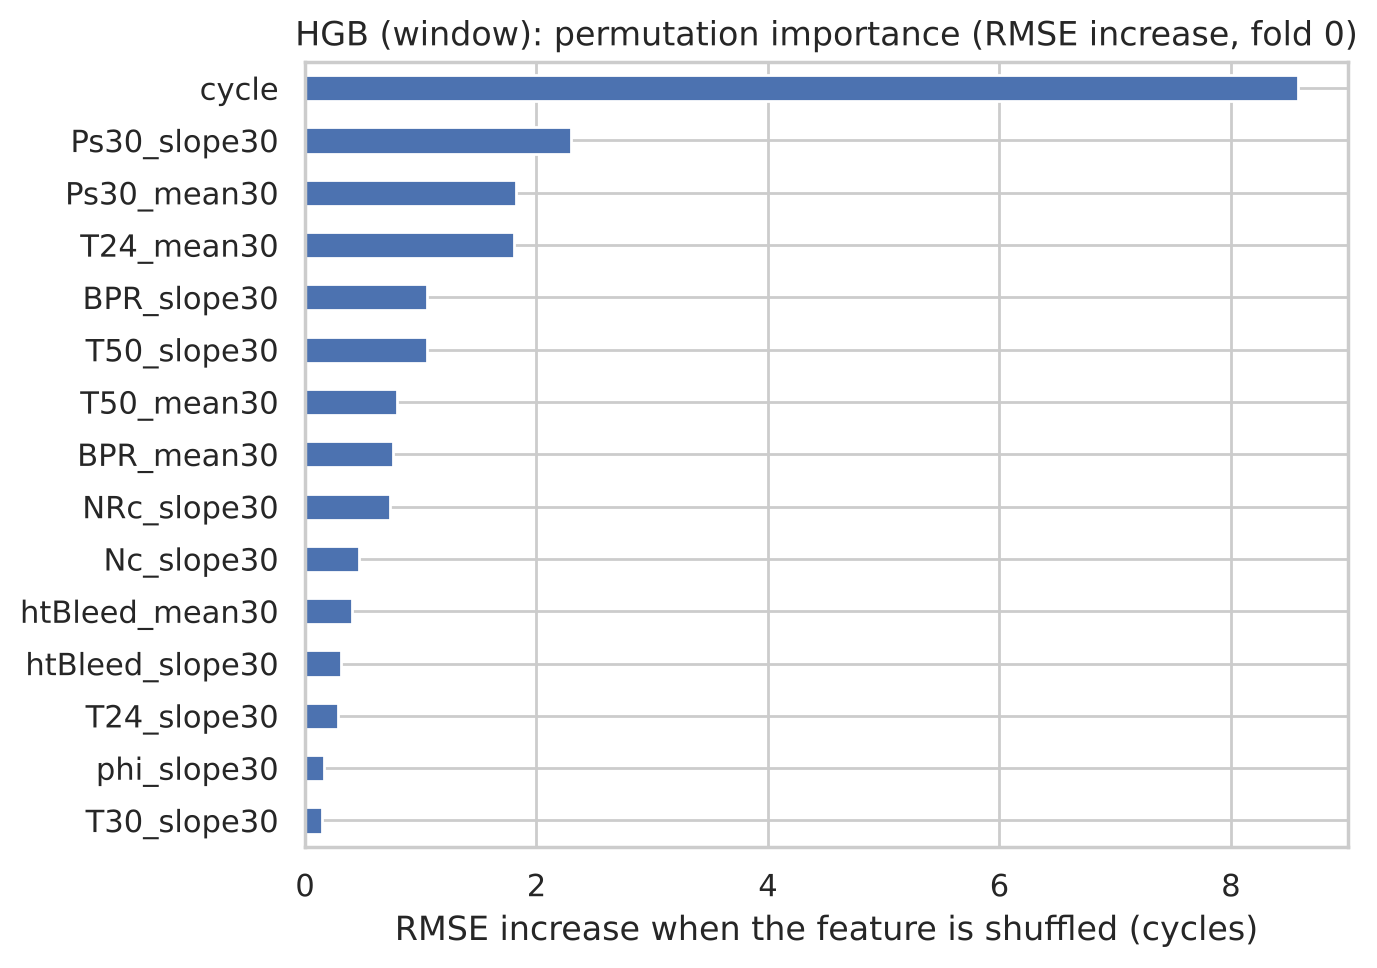

In [13]:
# Permutation importance on a VALIDATION fold (not on the test set, not on training data)
tr_idx, va_idx = folds[0]
m0 = clone(make_models()[best_name]).fit(X.iloc[tr_idx], y.iloc[tr_idx])
Xva = X.iloc[va_idx]
Fva = m0.named_steps['features'].transform(Xva)
head = Pipeline(m0.steps[1:])                                   # scaler + model, applied to the features
pi = permutation_importance(head, Fva, y.iloc[va_idx], scoring='neg_root_mean_squared_error',
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Fva.columns).sort_values(ascending=False)
imp.head(15)[::-1].plot.barh(figsize=(7, 5), title=f'{best_name}: permutation importance (RMSE increase, fold 0)')
plt.xlabel('RMSE increase when the feature is shuffled (cycles)'); plt.tight_layout(); plt.show()

## 8. Step 2 (to do with Lab 6) — where it plugs in
Everything below re-uses `pipe()`, `make_models()`, `folds` and `cross_validate_model()`; only new dictionary entries are needed.

1. **GridSearchCV** — always with the engine groups, never a plain `cv=5`:
   ```python
   gs = GridSearchCV(pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
                     param_grid={'model__learning_rate': [0.03, 0.1], 'model__max_depth': [None, 6],
                                 'features__window': [15, 30, 50]},
                     cv=GroupKFold(5), scoring='neg_root_mean_squared_error', n_jobs=-1)
   gs.fit(X, y, groups=groups)
   ```
   To report an *unbiased* score of the tuned model, wrap it in the outer loop: `cross_validate_model(gs, ...)` = **nested CV**
   (the inner `GroupKFold` needs `groups`: pass them through a small wrapper or use `GroupKFold` splits computed on the outer training part).
2. **BaggingRegressor** around the decision tree and around the SVR (`BaggingRegressor(estimator=SVR(...), n_estimators=10, max_samples=0.2)`
   also solves the SVR training-cost problem, instead of `SubsampledRegressor`).
3. **VotingRegressor** combining the best tuned models (e.g. bagged SVR + random forest + HGB), average of predictions.
4. Compare everything in the same CV table and test table as above, plus fit/inference time (Lab 6 asks for the trade-off performance / time / interpretability).

## 9. Conclusions of step 1

In [14]:
b = cv_mean.loc['Ridge (current cycle)', 'RMSE random cut']
print(f"Week-2 baseline CV RMSE: {b:.2f}")
for n in order:
    print(f"  {n:24s} {cv_mean.loc[n, 'RMSE random cut']:6.2f}  ({(cv_mean.loc[n, 'RMSE random cut'] / b - 1):+.0%} RMSE vs baseline)")

Week-2 baseline CV RMSE: 23.05
  HGB (window)              14.40  (-38% RMSE vs baseline)
  Random forest             14.68  (-36% RMSE vs baseline)
  SVR (window)              16.63  (-28% RMSE vs baseline)
  Decision tree             17.75  (-23% RMSE vs baseline)
  HGB (current cycle)       20.94  (-9% RMSE vs baseline)
  Ridge (window)            21.79  (-5% RMSE vs baseline)
  Ridge (current cycle)     23.05  (+0% RMSE vs baseline)


**Summary (numbers from the tables above):**
* **Features and model interact.** With the linear model, the window features gain only ~1.3 cycles (23.1 → 21.8). With current-cycle features,
  switching to gradient boosting gains ~2.1 (→ 20.9). Together they give 14.4, far more than the sum of the two effects: the window provides a
  de-noised degradation level and slope, and only a non-linear model can exploit how degradation accelerates near failure.
* **HGB (window) is selected on CV** (RMSE 14.4 ± 3.2, −38 % vs the Week-2 baseline). The random forest is statistically tied (14.7 ± 2.6) but ~9×
  slower to train. On the test set both give ≈ 13.1 (capped RUL), consistent with CV.
* **The single decision tree is clearly worse** (17.8) and has the largest fold-to-fold variation: high variance, the problem **Bagging** addresses in step 2.
* **SVR** (16.6) is limited by the 1-in-5 subsampling; bagging several SVRs on different subsamples is the natural fix.
* **Safety:** late predictions (> 10 cycles too late) on engines close to failure (RUL ≤ 50) drop from 50 % with the baseline to 6 %. Late errors
  remain for RUL 50–75 (median ≈ +12 cycles).
* **Engine age dominates:** `cycle` is by far the most important feature by permutation. It is legitimate (the age is known at prediction time),
  but removing it costs only a little (see the extra ablation), because the sensor means carry much of the same information. Note that permutation
  importance under-estimates correlated features (shuffling `T50_mean30` leaves `Ps30_mean30`, which says almost the same thing).
* **Not done yet (step 2):** no hyperparameter tuning, no ensembles of different models; long true RULs (> 125) remain capped by construction.